In [1]:
# --- Routing Workflow with Feedback + Tools ---
# Same as routing_with_feedback, but each node uses web search tools
# (Tavily/DuckDuckGo) to ground its output in external factual data.
from typing import Annotated, List, Literal, Optional, TypedDict,NotRequired
from pydantic import BaseModel, Field, field_validator, ValidationError
from operator import add
from langgraph.graph.message import add_messages
from langgraph.graph import StateGraph, END, START
from langgraph.graph.state import CompiledStateGraph
from IPython.display import Image, display, Markdown
import re

# Google
from langchain_google_genai import ChatGoogleGenerativeAI

# HuggingFace
# from langchain_huggingface.embeddings import HuggingFaceEndpointEmbeddings
# from langchain_huggingface import ChatHuggingFace, HuggingFaceEndpoint

# Cohere
from langchain_cohere import CohereEmbeddings

# Prompts
from langchain.prompts import PromptTemplate
from langchain_core.messages import BaseMessage
from langchain_core.messages import SystemMessage, HumanMessage, ToolMessage, AIMessage
# tools
from langchain_core.tools import tool
from langchain_community.tools import DuckDuckGoSearchRun
from langchain_tavily import TavilySearch
import json

# Others
import os
from dotenv import load_dotenv
# # LangSmith
# import uuid
# from langchain_core.tracers.context import collect_runs
# from langchain_core.tracers.langchain import wait_for_all_tracers
# from langsmith import Client
# from langchain.callbacks.tracers import LangChainTracer

c:\Users\Administrator\Desktop\llmai\llm_deep\Lib\site-packages\langgraph\checkpoint\base\__init__.py:21: LangChainPendingDeprecationWarning: The default value of `allowed_objects` will change in a future version. Pass an explicit value (e.g., allowed_objects='messages' or allowed_objects='core') to suppress this warning.
  from langgraph.checkpoint.serde.jsonplus import JsonPlusSerializer
c:\Users\Administrator\Desktop\llmai\llm_deep\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
c:\Users\Administrator\Desktop\llmai\llm_deep\Lib\site-packages\langchain_google_genai\chat_models.py:47: FutureWarning: 

All support for the `google.generativeai` package has ended. It will no longer be receiving 
updates or bug fixes. Please switch to the `google.genai` package as soon as possible.
See README for more details:

https

In [2]:
from dotenv import load_dotenv

# Provide the filename as a string
load_dotenv('.env')

True

In [3]:
# loadding Google token
GOOGLE_API_KEY = os.getenv("GOOGLE_AI_STUDIO_GENERATIVE_MODEL_API_KEY")
# using Google from langchain
google_llm = ChatGoogleGenerativeAI(
    model="gemini-2.5-flash",
    temperature=0.1,
    max_output_tokens=4096,
    api_key=GOOGLE_API_KEY
)

In [4]:
# loading Google token
GOOGLE_API_KEY = os.getenv("GOOGLE_AI_STUDIO_GENERATIVE_MODEL_API_KEY")
# using Google from langchain
google_llm_3_7 = ChatGoogleGenerativeAI(
    model="gemini-3.7-flash",
    temperature=0.1,
    max_output_tokens=4096,
    api_key=GOOGLE_API_KEY
)

## **Tool Definition**

In [5]:
# ================================================================
# Web Search Tool
# ================================================================

@tool
def web_search(query: str) -> str:
    """
    Searches the web for factual information regarding
    scientists, their history, and their achievements.

    Tavily is used as the external search provider.
    """

    try:

        # Create a Tavily search client.
        # max_results=1 keeps the amount of returned research small.
        search_tool = TavilySearch(
            max_results=1,
            topic="general",
            search_depth="basic",
            include_answer=True,
            include_raw_content=False,
        )

        # Execute the web search using the query supplied by Gemini.
        result = search_tool.invoke({
            "query": query
        })

        # Handle an empty response from Tavily.
        if not result:
            return "No search results were returned."

        # Store the useful parts of the search response.
        research_parts = []

        # ------------------------------------------------------------
        # Tavily's generated summary
        # ------------------------------------------------------------

        answer = result.get("answer")

        if answer:
            research_parts.append(
                f"SEARCH SUMMARY:\n{answer}"
            )

        # ------------------------------------------------------------
        # Individual search results
        # ------------------------------------------------------------

        results = result.get("results", [])

        for index, item in enumerate(results, start=1):

            title = item.get("title", "Untitled")
            url = item.get("url", "")
            content = item.get("content", "")

            research_parts.append(
                f"""
SOURCE {index}
Title: {title}
URL: {url}
Content:
{content}
""".strip()
            )

        # Handle a response that contains no usable information.
        if not research_parts:
            return "No useful external research was returned."

        # Combine the summary and source information into one string.
        return "\n\n".join(research_parts)

    except Exception as e:

        # Return the exception instead of hiding it.
        # This makes debugging the external search provider easier.
        return (
            f"WEB_SEARCH_ERROR: "
            f"{type(e).__name__}: {e}"
        )


# ================================================================
# Tool Registration
# ================================================================

# List of tools available to Gemini.
tools = [web_search]


# Create a lookup dictionary so Python can find a tool
# using the tool name returned by Gemini.
tools_by_name = {
    tool_obj.name: tool_obj
    for tool_obj in tools
}


# Bind the web_search tool to Gemini.
# Gemini can now decide when a web search is required.
llm_with_tools = google_llm.bind_tools(tools)

In [6]:
# example output of Tavily is 
# {'query': 'Stephen Hawking biography major scientific contributions', 'follow_up_questions': None, 'answer': "Stephen Hawking made major contributions to general relativity, including theorems on singularities and the prediction of Hawking radiation from black holes. His work on black holes and cosmology advanced understanding of the universe's origins and structure.", 'images': [], 'results': [{'url': 'https://en.wikipedia.org/wiki/Stephen_Hawking', 'title': 'Stephen Hawking', 'content': '> Hawking has made major contributions to the field of general relativity. These derive from a deep understanding of what is relevant to physics and astronomy, and especially from a mastery of wholly new mathematical techniques. Following the pioneering work of Penrose he established, partly alone and partly in collaboration with Penrose, a series of successively stronger theorems establishing the fundamental result that all realistic cosmological models must possess singularities. Using [...] Hawking\'s scientific works included a collaboration with Roger Penrose on gravitational singularity theorems in the framework of general relativity, and the theoretical prediction that black holes emit radiation, often called Hawking radiation. Initially, Hawking radiation was controversial. By the late 1970s, and following the publication of further research, the discovery was widely accepted as a major breakthrough in theoretical physics. Hawking was the first to set out a theory of cosmology [...] "Great Debates (international relations)") (1980s)  Science wars (1990s) | | Contributions |  The Course in Positive Philosophy (1830)  A General View of Positivism (1848)  Critical History of Philosophy (1869)  Idealism and Positivism (1879–1884)  The Analysis of Sensations (1886)  The Logic of Modern Physics (1927)  Language, Truth, and Logic (1936)  The Two Cultures (1959)  The Universe in a Nutshell (2001) | | Proponents |  Richard Avenarius  A. J. Ayer  Berlin Circle / Vienna Circle', 'score': 0.9721515, 'raw_content': None, 'id': 'b3985c-00'}], 'response_time': 0.0, 'request_id': '95d216c1-fcf8-4444-bc11-3746591db2aa'}

## **Inline Research Helper Function for Tools**

In [7]:
# ================================================================
# Research Helper
# ================================================================

def perform_research_with_tools(query_prompt: str) -> str:
    """
    Allows Gemini to decide whether web_search should be used.

    Flow:

        Research request
                ↓
        Gemini + bound web_search tool
                ↓
        Gemini requests web_search
                ↓
        Python executes Tavily
                ↓
        Tavily returns search results
                ↓
        Results are returned to the calling graph node

    IMPORTANT:

    I deliberately do NOT send Gemini's original AIMessage
    containing tool-call metadata back to Gemini.

    This avoids the compatibility/serialization problem that
    can produce:

        'int' object has no attribute 'name'
    """

    # ------------------------------------------------------------
    # Build the initial conversation for Gemini.
    # ------------------------------------------------------------

    messages = [
        SystemMessage(
            content=(
        "You are a research assistant. "
        "Decide whether web_search is necessary to answer "
        "the user's request accurately. "
        "Use web_search when external factual information "
        "is needed or would materially improve accuracy. "
        "If web search is not necessary, answer directly."
            )
        ),
        HumanMessage(content=query_prompt),
    ]

    try:

        # ========================================================
        # 1. ASK GEMINI WHETHER A TOOL SHOULD BE USED
        # ========================================================

        # Gemini receives the request together with the available
        # web_search tool and decides whether to call it.
        response = llm_with_tools.invoke(messages)

        # LangChain exposes Gemini's requested tools through
        # the tool_calls attribute.
        tool_calls = getattr(response, "tool_calls", None)


        # ========================================================
        # 2. GEMINI DID NOT REQUEST A TOOL
        # ========================================================

        if not tool_calls:

            # If Gemini decided that no web search is necessary,
            # return its response directly.
            return str(response.content)


        # ========================================================
        # 3. EXECUTE GEMINI'S TOOL CALLS
        # ========================================================

        # Store the results returned by each requested tool.
        research_results = []

        for tool_call in tool_calls:

            # Gemini/LangChain normally returns tool calls as
            # dictionaries. Ignore anything unexpected.
            if not isinstance(tool_call, dict):
                continue


            # ----------------------------------------------------
            # Get the requested tool name
            # ----------------------------------------------------

            tool_name = tool_call.get("name")

            if not tool_name:
                continue


            # ----------------------------------------------------
            # Find the corresponding Python tool
            # ----------------------------------------------------

            tool_obj = tools_by_name.get(tool_name)

            if tool_obj is None:

                research_results.append(
                    f"Unknown tool requested: {tool_name}"
                )

                continue


            # ----------------------------------------------------
            # Extract the arguments Gemini supplied
            # ----------------------------------------------------

            tool_args = tool_call.get("args", {})

            if tool_args is None:
                tool_args = {}


            # Gemini normally returns arguments in this format:
            #
            # {
            #     "query": "Stephen Hawking biography..."
            # }
            #
            # Convert unexpected string arguments into a dictionary.

            if isinstance(tool_args, str):

                try:

                    tool_args = json.loads(tool_args)

                except json.JSONDecodeError:

                    # If the string is not JSON, treat the entire
                    # string as the search query.
                    tool_args = {
                        "query": tool_args
                    }


            # If Gemini returns another unexpected argument type,
            # convert it into a valid query dictionary.
            if not isinstance(tool_args, dict):

                tool_args = {
                    "query": str(tool_args)
                }


            # ----------------------------------------------------
            # Safety fallback for a missing query
            # ----------------------------------------------------

            # If Gemini fails to provide a search query, use the
            # original research request instead.
            if not tool_args.get("query"):

                tool_args["query"] = query_prompt


            # ====================================================
            # 4. EXECUTE THE SELECTED TOOL
            # ====================================================

            try:

                # This executes the Tavily web search.
                observation = tool_obj.invoke(tool_args)

                # Store the returned research if anything was found.
                if observation:

                    research_results.append(
                        str(observation)
                    )

            except Exception as e:

                # Preserve the error in the research output so that
                # the calling node can see that the search failed.
                research_results.append(
                    f"WEB_SEARCH_ERROR: "
                    f"{type(e).__name__}: {e}"
                )


        # ========================================================
        # 5. RETURN THE RESEARCH TO THE GRAPH NODE
        # ========================================================

        if research_results:

            # Combine results from all requested tool calls.
            return "\n\n".join(research_results)

        # Gemini requested a tool, but no useful result was produced.
        return "No useful external research was returned."


    except Exception as e:

        # This catches failures occurring during Gemini's
        # tool-selection stage rather than inside Tavily itself.
        print(
            f"Research tool-selection failed: "
            f"{type(e).__name__}: {e}"
        )

        return (
            f"Research unavailable: "
            f"{type(e).__name__}: {e}"
        )

## **Pydantic: Validation Logic for Routing**

In [8]:
class Route(BaseModel):
    step: Literal["history", "accomplishment","article"] = Field(
        description="The next step of the workflow process."
    )

In [9]:
router = google_llm.with_structured_output(Route)

## **Pydantic: Validation Logic for each node**

In [10]:
# Pydantic: Validate external input
class ScientistInput(BaseModel):
    scientist: str = Field( min_length=3,max_length=100, 
    description="The name of the scientist"
    )

    @field_validator("scientist")
    def validate_scientist(cls, value):
        value = value.strip()
        if not re.search("[a-zA-Z]", value):
            raise ValueError("Scientist name must contain letters.")
        return value.strip()

In [11]:
# Pydantic: Validate LLM outputs
class ScientistHistoryOutput(BaseModel):
    history: str = Field(description="The history of the scientist")

class ScientistAchievementsOutput(BaseModel):
    achievements: list[str] = Field(description="Five major achievements of the scientist")

class ScientistArticleOutput(BaseModel):
    article: str = Field(description="Detailed article about the scientist")

class RefinedArticleOutput(BaseModel):
    refined_article: str = Field(description="Refined article about the scientist under 1000 words")

# Evaluator/Feedback/Critic
class EvaluatorCritic(BaseModel):
    status: Literal["ACCEPTED", "REJECTED"] = Field(
        description="Decide if the Refined Article is acceptable or not"

    )

    feedback: str = Field(
        description="Give a constructive reason why the article is not good enougn with points for improvement"
    )

In [12]:
# Structured LLMs 
history_llm = google_llm.with_structured_output(ScientistHistoryOutput)
achievements_llm = google_llm.with_structured_output(ScientistAchievementsOutput)
article_llm = google_llm.with_structured_output(ScientistArticleOutput)
refined_article_llm = google_llm.with_structured_output(RefinedArticleOutput)

# Evaluator/Feedback/Critic
evaluator_llm = google_llm_3_7.with_structured_output(EvaluatorCritic)

## **Define Graph State**

In [13]:
# Graph State
class State(TypedDict):
    # For routing
    input: str
    decision: NotRequired[str]
    scientist: NotRequired[str]
    history: NotRequired[str]
    achievements: NotRequired[list[str]]
    article: NotRequired[str]
    refined_article: NotRequired[str] # or NotRequired[Optional[str]]

    # EvaluatorCritic
    feedback: NotRequired[str]
    accepted_rejected: NotRequired[str]
    feedback_count: NotRequired[int] # Crucial: Persist loop count in state

## **Defining the Nodes**

In [14]:
def generate_history(state: State):
    scientist = state.get("scientist", "")

    try:
        research_data = perform_research_with_tools(
            f"Research key biographical history of {scientist}."
        )

        print("\n--- RESEARCH RESULT ---")
        print(research_data)
        print("--- END RESEARCH RESULT ---\n")

        prompt = PromptTemplate.from_template("""
        Provide a brief and accurate history of {scientist}.

        Use the following research information where relevant:

        {research}

        Do not mention the research process.
        """)

        history_chain = prompt | history_llm

        information_data = {
            "scientist": scientist,
            "research": research_data
        }

        response = history_chain.invoke(information_data)

        if response and hasattr(response, "history"):
            return {"history": response.history}

        return {
            "history": "History unavailable."
        }

    except Exception as e:
        print(f"History generation failed: {e}")

        return {
            "history": f"Failed to generate history: {e}"
        }

In [15]:
# Defining the nodes
def generate_achievements(state:State):
    scientist = state.get("scientist", "")
    try:
        research_data = perform_research_with_tools(
            f"Research the 5 most important achievements of {scientist}."
        )

        print("\n--- ACHIEVEMENT RESEARCH ---")
        print(research_data)
        print("--- END ACHIEVEMENT RESEARCH ---\n")
        prompt = PromptTemplate.from_template(
    """Provide 5 top achievements of {scientist} in bullet points.
    Example:
    - Achievement 1
    - Achievement 2
    - Achievement 3
    - Achievement 4
    - Achievement 5
    \n
    Use the extra information from a research if needed: 
    {research}
    """
    )
        achievement_chain = prompt | achievements_llm
        information_data = {"scientist": scientist, "research": research_data}
        response = achievement_chain.invoke(information_data)
        
        if response and hasattr(response, "achievements") and response.achievements:
            achievements_list_text = "\n".join([f"- {ach}" for ach in response.achievements])
        else:
            achievements_list_text = "- Information unavailable"
    except Exception as e:
        achievements_list_text = f"- Achievements generation failed: {str(e)}"
    # forgot to return  the response
    # CRITICAL FIX: Return the dictionary to update the graph state!
    return {"achievements": achievements_list_text}

In [16]:
# Defining the nodes
def generate_article(state:State):
    try:
        # Prompt to get the scientist's information
        prompt = PromptTemplate.from_template(
        """Provide an in depth article about {scientist} based on the following information:
        History: {history}
        Achievements: {achievements}
        Final Article must be in Markdown format with different sections. For example;
        ## **Title**

        ### **History**

        ### **Achievements**

        ### **Main Contributions**

        ## **Conclusion**

        This is just an example you can modify

        You must give the article in Markdown format
        """
        )
        
        information_data = {"scientist": state["scientist"], 
                            "history": state["history"], 
                            "achievements": state["achievements"] 
                            }
        article_chain = prompt | article_llm
        response = article_chain.invoke(information_data)

        # Returning the response as a dictionary with the key "article"
        article_text = response.article if (response and hasattr(response, "article")) else "Generation failed."
        return {"article": article_text}
    except Exception as e:
        article_text = f"Article generation error: {str(e)}"
        return {"article": article_text}

In [17]:
# Defining the nodes
def generate_refined_article(state:State):
    # Prompt to get the scientist's information
    # Safely retrieve 'article' using .get() to prevent KeyError
    generated_article = state.get("article", "")
    current_count = state.get("feedback_count", 0)
    
    if not generated_article:
        return {"refined_article": "Error: Article was not generated properly."}
        

    article_length = len(generated_article.split())
    if article_length > 1000:
        prompt = PromptTemplate.from_template(
        """Summarise the following article about {scientist} in less than 1000 words from given article\n{article}.\n
        It should be concise and clear, and should not lose the main points of the article. 
        Final Article must be in Markdown format with different sections. For example;
        ## **Title**

        ### **History**

        ### **Achievements**

        ### **Main Contributions**
        
        ## **Conclusion**

        This is just an example you can modify
        You must give the article in Markdown format
        """
        )
        refined_article_data = {"scientist": state["scientist"], "article": generated_article}
        refined_article_chain = prompt | refined_article_llm
        response = refined_article_chain.invoke(refined_article_data)

        refined_text = response.refined_article if (response and hasattr(response, "refined_article")) else generated_article
        # Returning the response as a dictionary with the key "refined_article"
        return {"refined_article": refined_text, "feedback_count": current_count}
    else:
        print("Initial article is already under 1000 words. No refinement needed.")
        return {"refined_article": generated_article,
                "feedback_count": current_count        
        }

In [18]:
# Revises the article using evaluator feedback; increments feedback_count
def refine_article_with_feedback(state: State):
    generated_article = state.get("article", "")
    # Ensure a fallback to generated_article if refined_article is empty string ""
    existing_refined = state.get("refined_article") or generated_article
    current_count = state.get("feedback_count", 0)

    feedback_prompt = PromptTemplate.from_template(
        """Improve the refined article\n{refined_article}.\nWith the provided feedback \n{feedback}
        You must give the article in Markdown format.
        """
    )
    feedback_data = {
        #"refined_article": state.get("refined_article", generated_article),
        # Becasue of the updated codebase, we now use existing_refined
        "refined_article": existing_refined,
        "feedback": state["feedback"]
    }
    
    feedback_chain = feedback_prompt | refined_article_llm
    response = feedback_chain.invoke(feedback_data)
    
    # refined_text = response.refined_article if (response and hasattr(response, "refined_article"))  else generated_article
    refined_text = response.refined_article if (response and hasattr(response, "refined_article") and response.refined_article) else existing_refined
    current_count+=1
    print(f"Article was rejected {current_count} time(s)!")
    return {
        "refined_article": refined_text,
        "feedback_count": current_count 
    }

In [19]:
# LLM critic evaluates the refined article and returns ACCEPTED/REJECTED with feedback
def llm_evaluator(state: State):
    """Evaluation of Articles"""
    refined_text = state.get("refined_article", state.get("article", ""))
    try:
        critic = evaluator_llm.invoke([
            SystemMessage(content="You are an expert critic. Evaluate the provided article."),
            HumanMessage(content=f"Article:\n{refined_text}")
        ])
        status = critic.status if (critic and hasattr(critic, "status")) else "REJECTED"
        feedback = critic.feedback if (critic and hasattr(critic, "feedback")) else "Evaluation error."
    except Exception as e:
        status = "REJECTED"
        feedback = f"Error: {str(e)}"

    return {"accepted_rejected": status, "feedback": feedback}

In [20]:

# Returns ACCEPTED if max retries (3) reached, otherwise passes through evaluator verdict
def route_feedback(state:State):
    """Route the refined article or end based upon the feedback from the evaluator"""
    if state.get("feedback_count", 0) >= 3:
        return "ACCEPTED"
    return state.get("accepted_rejected", "ACCEPTED")

In [21]:
# LLM classifies input into one of the predefined route categories
def llm_routing(state: State):
    prompt = PromptTemplate.from_template(
    """Route the workflow based on the input provided by the user. 
    - If the input is asking for a history of a scientist, route to 'history'. 
    - If the input is asking for achievements of a scientist, route to 'accomplishment'. 
    - If the input is asking for an article about a scientist, route to 'article'. Especially if the input is asking for both history and achievements, route to 'article'.
    The input is: {input}.
    """
    )

    router_data  = {"input": state["input"]}
    router_chain  = prompt | router
    decision = router_chain.invoke(router_data)

    return {"decision": decision.step}

In [22]:
# Maps LLM decision string to next node name
def route_decision(state:State):
    decision = state.get("decision", "")
    if decision == "history":
        return "generate_history"
    elif decision == "accomplishment":
        return "generate_achievements"
    elif decision == "article":
        return "article_workflow"
    raise ValueError(f"Invalid decision: {decision}")

In [23]:
# Extracts the scientist's name from the user input via LLM
def scientist_name_extraction(state:State):
    # Extract the scientist's name from the input
    prompt = PromptTemplate.from_template(
    """Extract the scientist's name from the input provided by the user. 
    The input is: {input}.
    """
    )

    extraction_data  = {"input": state["input"]}
    extraction_chain  = prompt | google_llm
    response = extraction_chain.invoke(extraction_data)

    try:
        validated = ScientistInput.model_validate(
                    {
                    "scientist": response.content.strip()
                    }
        )
        # Assuming the response contains the extracted name in a field called 'content'
        return {"scientist": validated.scientist}

    except ValidationError as e:
        print(e.errors()[0]["msg"])

## **Building the Graph**

In [24]:
# Article subgraph: parallel history+achievements -> article -> refine -> feedback loop
def build_article_workflow():
    article_workflow = StateGraph(State)
    article_workflow.add_node("generate_history", generate_history)
    article_workflow.add_node("generate_achievements", generate_achievements)
    article_workflow.add_node("generate_article", generate_article)
    article_workflow.add_node("generate_refined_article", generate_refined_article)
    article_workflow.add_node("refine_article_with_feedback", refine_article_with_feedback)  # NEW NODE
    article_workflow.add_node("evaluate_feedback_llm",llm_evaluator)

    # start both in parallel
    article_workflow.add_edge(START, "generate_history")
    article_workflow.add_edge(START, "generate_achievements")
    article_workflow.add_edge("generate_history", "generate_article")
    article_workflow.add_edge("generate_achievements", "generate_article")
    article_workflow.add_edge("generate_article", "generate_refined_article")

    # Feeback Route
    article_workflow.add_edge("generate_refined_article", "evaluate_feedback_llm")
    
    # adding the evaluation path
    article_workflow.add_edge("refine_article_with_feedback", "evaluate_feedback_llm")
    article_workflow.add_conditional_edges(
        "evaluate_feedback_llm",
        route_feedback,
        {
            "ACCEPTED": END,
            "REJECTED": "refine_article_with_feedback" # Routes directly to feedback node
        }
    )

    return article_workflow.compile()
    
        

In [25]:
# Builds the main graph with extraction -> routing -> conditional edges
def build_main_graph():    
    workflow = StateGraph(State)

    # Build article subgraph
    article_workflow = build_article_workflow()

    # Registering the nodes
    workflow.add_node("scientist_name_extraction", scientist_name_extraction)
    workflow.add_node("generate_history", generate_history)
    workflow.add_node("generate_achievements", generate_achievements)
    workflow.add_node("article_workflow", article_workflow)
    workflow.add_node("llm_routing", llm_routing)

    # START
    workflow.add_edge(START, "scientist_name_extraction")
    workflow.add_edge("scientist_name_extraction", "llm_routing")

    # ROUTING LOGIC
    workflow.add_conditional_edges(
        "llm_routing", route_decision,
    {
        # name returned by route_decision function: name of the next node to execute
        "generate_history": "generate_history",
        "generate_achievements": "generate_achievements",
        "article_workflow": "article_workflow",
    }
    )

    # SIMPLE ROUTES
    workflow.add_edge("generate_history", END)
    workflow.add_edge("generate_achievements", END)
    workflow.add_edge("article_workflow", END)

    return workflow.compile()

In [26]:
graph = build_main_graph()
article_workflow = build_article_workflow()

In [27]:
# Renders the LangGraph workflow as a Mermaid diagram
def graph_visualiser(graph):
    try:
        display(Image(graph.get_graph().draw_mermaid_png()))
    except Exception as e:
        print(e)

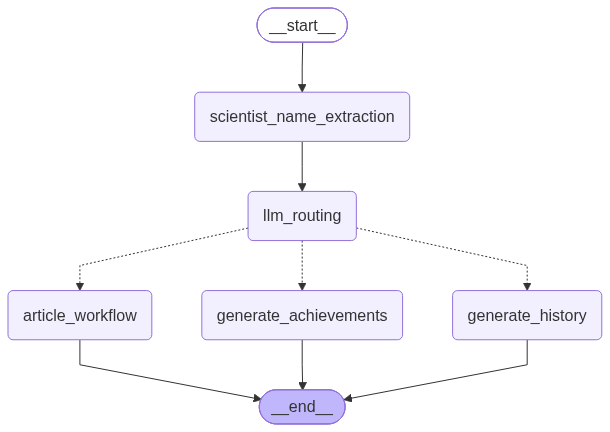

In [28]:
graph_visualiser(graph)

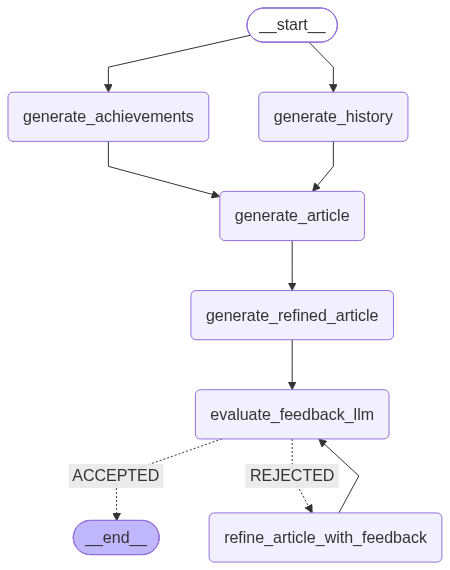

In [29]:
# article_workflow
graph_visualiser(article_workflow)

In [30]:
# Formats and displays all state fields using IPython Markdown rendering
def results_formatting(results:dict):
    """The Results formatter"""
    for key,value in results.items():
        if not isinstance(value, int):
            print(f"{key.upper()}")
            display(Markdown(value.strip()))
        else:
            print(f"{key.upper()}\n{value}\n")

In [31]:
# Example usage
results = graph.invoke(
    {
        "input": "Tell me about Albert Einstein's history",
    }
)


--- RESEARCH RESULT ---
SEARCH SUMMARY:
Albert Einstein was born on March 14, 1879, in Ulm, Germany, and died on April 18, 1955, in Princeton, New Jersey, USA. He is best known for his theories of relativity, which revolutionized modern physics.

SOURCE 1
Title: Albert Einstein (1879 - 1955) - Biography - MacTutor History of Mathematics
URL: https://mathshistory.st-andrews.ac.uk/Biographies/Einstein
Content:
Skip to content

Home Biographies History Topics Map Curves Search

# Albert Einstein

### Quick Info

Born
:   14 March 1879   
      Ulm, Württemberg, Germany

Died
:   18 April 1955   
     Princeton, New Jersey, USA

Summary
:   Einstein contributed more than any other scientist to the modern vision of physical reality. His special and general theories of relativity are still regarded as the most satisfactory model of the large-scale universe that we have. [...] 36. G Holton and Y Elkana (eds.), Albert Einstein : Historical and cultural perspectives (Princeton, NJ, 1982).
37. 

In [32]:
results

{'input': "Tell me about Albert Einstein's history",
 'decision': 'history',
 'scientist': 'Albert Einstein',
 'history': 'Albert Einstein was born on March 14, 1879, in Ulm, Germany, and died on April 18, 1955, in Princeton, New Jersey, USA. He is best known for his special and general theories of relativity, which revolutionized modern physics and are still regarded as the most satisfactory model of the large-scale universe.'}

In [33]:
results_formatting(results)

INPUT


Tell me about Albert Einstein's history

DECISION


history

SCIENTIST


Albert Einstein

HISTORY


Albert Einstein was born on March 14, 1879, in Ulm, Germany, and died on April 18, 1955, in Princeton, New Jersey, USA. He is best known for his special and general theories of relativity, which revolutionized modern physics and are still regarded as the most satisfactory model of the large-scale universe.

In [34]:
# Example usage
results = graph.invoke(
    {
        "input": "Tell me about Albert Einstein's achievements",
    }
)


--- ACHIEVEMENT RESEARCH ---
SEARCH SUMMARY:
Albert Einstein's most important achievements include the Special Theory of Relativity, General Theory of Relativity, and his work on the photoelectric effect, which won him the Nobel Prize. His contributions fundamentally changed physics.

SOURCE 1
Title: Albert Einstein – Biographical
URL: https://www.nobelprize.org/prizes/physics/1921/einstein/biographical
Content:
Einstein’s researches are, of course, well chronicled and his more important works include Special Theory of Relativity (1905), Relativity (English translations, 1920 and 1950), General Theory of Relativity (1916), Investigations on Theory of Brownian Movement (1926), and The Evolution of Physics (1938). Among his non-scientific works, About Zionism (1930), Why War? (1933), My Philosophy (1934), and Out of My Later Years (1950) are perhaps the most important.
--- END ACHIEVEMENT RESEARCH ---



In [35]:
results

{'input': "Tell me about Albert Einstein's achievements",
 'decision': 'accomplishment',
 'scientist': 'Albert Einstein',
 'achievements': '- Developed the Special Theory of Relativity\n- Formulated the General Theory of Relativity\n- Explained the photoelectric effect, for which he received the Nobel Prize\n- Provided a theory of Brownian motion\n- Derived the mass-energy equivalence formula (E=mc²)'}

In [36]:
results_formatting(results)

INPUT


Tell me about Albert Einstein's achievements

DECISION


accomplishment

SCIENTIST


Albert Einstein

ACHIEVEMENTS


- Developed the Special Theory of Relativity
- Formulated the General Theory of Relativity
- Explained the photoelectric effect, for which he received the Nobel Prize
- Provided a theory of Brownian motion
- Derived the mass-energy equivalence formula (E=mc²)

In [37]:
results = graph.invoke(
    {
        "input": "Give me an article about Albert Einstein",
    }
)


--- ACHIEVEMENT RESEARCH ---
SEARCH SUMMARY:
Albert Einstein's most important achievements include the Special Theory of Relativity, General Theory of Relativity, and his work on the photoelectric effect, which won him the Nobel Prize. His contributions fundamentally changed physics.

SOURCE 1
Title: Albert Einstein – Biographical
URL: https://www.nobelprize.org/prizes/physics/1921/einstein/biographical
Content:
Einstein’s researches are, of course, well chronicled and his more important works include Special Theory of Relativity (1905), Relativity (English translations, 1920 and 1950), General Theory of Relativity (1916), Investigations on Theory of Brownian Movement (1926), and The Evolution of Physics (1938). Among his non-scientific works, About Zionism (1930), Why War? (1933), My Philosophy (1934), and Out of My Later Years (1950) are perhaps the most important.
--- END ACHIEVEMENT RESEARCH ---


--- RESEARCH RESULT ---
SEARCH SUMMARY:
Albert Einstein was born on March 14, 1879, 

In [38]:
results

{'input': 'Give me an article about Albert Einstein',
 'decision': 'article',
 'scientist': 'Albert Einstein',
 'history': 'Albert Einstein was born on March 14, 1879, in Ulm, Germany, and died on April 18, 1955, in Princeton, New Jersey, USA. He is best known for his special and general theories of relativity, which revolutionized modern physics and are still regarded as the most satisfactory model of the large-scale universe. Einstein contributed more than any other scientist to the modern vision of physical reality.',
 'achievements': '- Special Theory of Relativity\n- General Theory of Relativity\n- Work on the photoelectric effect\n- Investigations on Theory of Brownian Movement\n- Awarded the Nobel Prize in Physics',
 'article': "## **Albert Einstein: A Revolutionary Mind in Physics**\n\n### **History**\n\nAlbert Einstein, one of the most influential physicists of all time, was born on March 14, 1879, in Ulm, Germany. His intellectual journey led him to become a pivotal figure in

In [39]:
results_formatting(results)

INPUT


Give me an article about Albert Einstein

DECISION


article

SCIENTIST


...

FEEDBACK


The article is well-structured, factually accurate, and covers Albert Einstein's key biographical details, major breakthroughs (relativity, photoelectric effect, Brownian motion), Nobel prize, and long-lasting legacy effectively. The prose is clear, informative, and engaging.

ACCEPTED_REJECTED


ACCEPTED

FEEDBACK_COUNT
0



In [40]:
results = graph.invoke(
    {
        "input": "Give me about Albert Einstein's history and article",
    }
)


--- ACHIEVEMENT RESEARCH ---
SEARCH SUMMARY:
Albert Einstein's most important achievements include the Special Theory of Relativity, General Theory of Relativity, and his work on the photoelectric effect, which won him the Nobel Prize. His contributions fundamentally changed physics.

SOURCE 1
Title: Albert Einstein – Biographical
URL: https://www.nobelprize.org/prizes/physics/1921/einstein/biographical
Content:
Einstein’s researches are, of course, well chronicled and his more important works include Special Theory of Relativity (1905), Relativity (English translations, 1920 and 1950), General Theory of Relativity (1916), Investigations on Theory of Brownian Movement (1926), and The Evolution of Physics (1938). Among his non-scientific works, About Zionism (1930), Why War? (1933), My Philosophy (1934), and Out of My Later Years (1950) are perhaps the most important.
--- END ACHIEVEMENT RESEARCH ---


--- RESEARCH RESULT ---
SEARCH SUMMARY:
Albert Einstein was born in Ulm, Germany, in

In [41]:
results

{'input': "Give me about Albert Einstein's history and article",
 'decision': 'article',
 'scientist': 'Albert Einstein',
 'history': 'Albert Einstein was born in Ulm, Germany, on March 14, 1879. He was a theoretical physicist who developed the general theory of relativity and is widely recognized for his mass-energy equivalence formula, E=mc². He received the Nobel Prize in Physics in 1921 for his services to theoretical physics, particularly for his discovery of the photoelectric effect. As a child, Einstein showed great curiosity for science and developed a lifelong passion for music, playing both the violin and piano. He moved to Italy and then Switzerland, graduating from high school in 1896.',
 'achievements': '- Developed the Special Theory of Relativity\n- Formulated the General Theory of Relativity\n- Explained the Photoelectric Effect, earning him the Nobel Prize\n- Provided the Theory of Brownian Movement\n- Discovered the mass-energy equivalence formula (E=mc²)',
 'article'

In [42]:
results_formatting(results)

INPUT


Give me about Albert Einstein's history and article

DECISION


article

SCIENTIST


...

FEEDBACK


The article is well-structured, factually accurate, and comprehensively covers Albert Einstein's early life, the 1905 Annus Mirabilis papers, General Relativity, his Nobel Prize, emigration to the United States, and his later advocacy for peace and civil rights. The tone is informative and engaging, and the formatting is clean and easy to read.

ACCEPTED_REJECTED


ACCEPTED

FEEDBACK_COUNT
1



## **Testing Errors**

In [43]:
# This is GOOD! Now we can test the routing logic with an input 
# that doesn't match any of the expected patterns.
results = graph.invoke(
    {
        "input": "Give me about 123 history"
    }
)


--- RESEARCH RESULT ---
It looks like you've provided a placeholder "No scientist's name was found in the input." Could you please provide the name of the scientist you'd like me to research?
--- END RESEARCH RESULT ---



In [44]:
# This is GOOD! Now we can test the routing logic with an input 
# that doesn't match any of the expected patterns.
results = graph.invoke(
    {
        "input": "Give me about ka history"
    }
)

String should have at most 100 characters

--- RESEARCH RESULT ---
Please provide the name of the person you would like me to research.
--- END RESEARCH RESULT ---

